# Pneumatic Particle Separation in a Variable-Diameter Pulsed-Airflow Separator

## Project check-in

**Authors.** Stuart Schultz, Yogesh Panchal, Meining Miao

November 13, 2026

## 1. Introduction

Spent lithium-ion batteries are a growing source of copper, aluminum and electrode materials, and mechanical pretreatment is the first step of most recycling routes (Harper et al., 2019). After crushing and sieving, the fraction coarser than 0.25 mm consists mainly of flakes of the copper and aluminum current collectors, which must be separated from each other before either metal can be reused. Zhu et al. (2021) do this with a pulsated pneumatic separator that has a variable-diameter section. Air flows upward through a vertical column, the feed enters at the widest section, aluminum leaves with the air at the top (overflow, light product) and copper falls to the bottom (underflow, heavy product). They recover 92.08% of the copper and 96.68% of the aluminum, and for each sieve class they find an optimal air flow rate between 75 and 89 m$^3$/h.

The separation rests on the suspension velocity, the upward gas velocity at which drag balances the weight of a particle. Zhu et al. measure 2.21 m/s for aluminum and 3.93 m/s for copper foils of 5 mm $\times$ 5 mm $\times$ 0.1 mm and compare three correlations for it. Their study does not model how the pulsation, the variable diameter and the interaction between particles turn this difference into the measured recovery and grade. Li et al. (2023) give a force balance for a single particle in a pulsed, variable-diameter separator for coal, with drag, gravity, buoyancy, the pressure-gradient force and added mass.

This project builds a particle-level model of the separator of Zhu et al. on that force balance. The aim is to predict where each particle leaves the column from the geometry, the air flow and the properties of the foils, and from many particles to predict the recovery and grade of both products as functions of the air flow rate, so that the roles of the pulsation and of the variable-diameter section can be examined.

Section 2 describes the model and Section 3 lists its simplifications. Section 4 first checks the gas velocity field and then reports results at three levels, the suspension velocity of a foil, the fate of single particles over the operating range, and a multi-particle simulation with collisions that yields recovery and grade curves, which are compared with the measurements of Zhu et al. Section 5 explains how the project has progressed since the proof of concept and Section 6 lists the remaining work.

## 2. Model

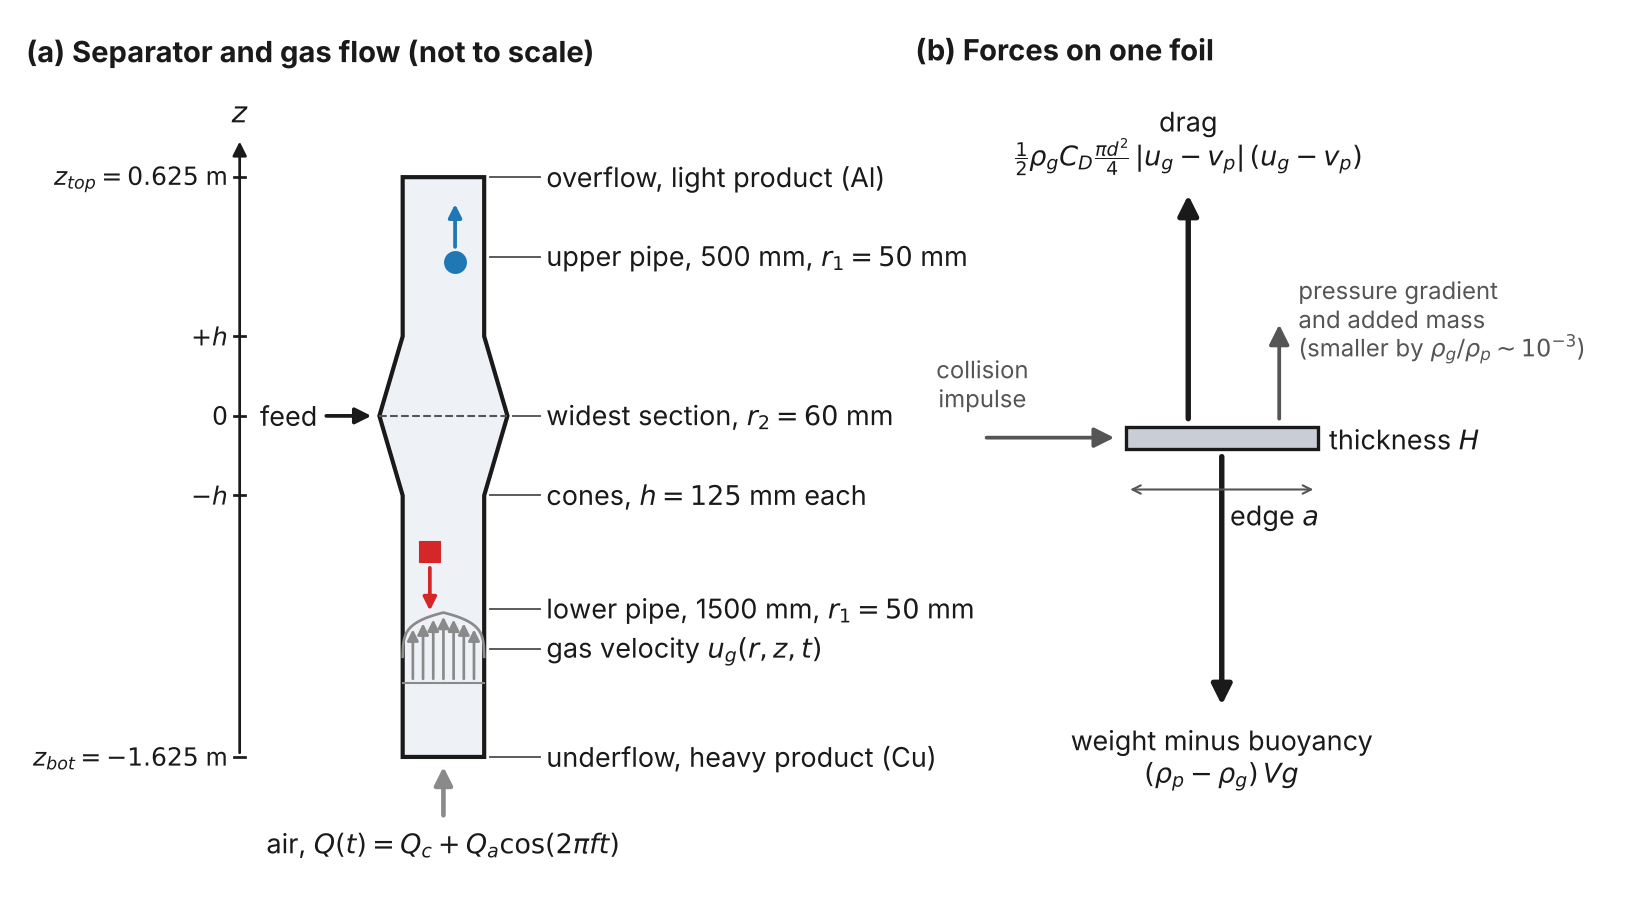

*Figure 1. (a) Separator geometry, coordinate system, outlets and gas flow. (b) Forces on one foil of edge $a$ and thickness $H$.*

### 2.1 Separator geometry

The separator consists of two straight pipes of radius $r_1 = 50$ mm joined by a double cone that widens to $r_2 = 60$ mm (Figure 1a). With $z$ measured upward from the widest section, where the feed enters, the wall radius and the cross-sectional area are

$$ r_w(z) = r_2 - (r_2 - r_1)\,\frac{|z|}{h} \quad (|z| \le h), \qquad r_w(z) = r_1 \quad (|z| > h), \qquad A(z) = \pi\, r_w(z)^2 , $$

with $h = 125$ mm for each cone, reading the 250 mm given by Zhu et al. (2021) as the height of both cones together. The upper pipe is 500 mm long and the lower pipe 1500 mm, so a particle leaves through the overflow at $z_{top} = 0.625$ m or through the underflow at $z_{bot} = -1.625$ m.

### 2.2 Gas flow

Air is treated as incompressible, so the same volume flow $Q(t)$ passes every cross-section at any instant. The blower sets a mean flow $Q_c$ and the pulsator adds a periodic part,

$$ Q(t) = Q_c + Q_a \cos(2\pi f t), \qquad 0 \le Q_a \le Q_c , $$

and continuity gives the cross-sectional mean velocity

$$ \bar u(z,t) = \frac{Q(t)}{A(z)} . $$

$Q(t)$ is prescribed, and the pressure-driven momentum balance of the air is not solved. Zhu et al. do not report the frequency or the amplitude of the pulsation. The baseline here is $f = 1$ Hz and $Q_a = 0.8\,Q_c$, and steady flow ($Q_a = 0$) is computed alongside it.

For $Q_c$ between 70 and 110 m$^3$/h the pipe Reynolds number $2 r_1 \bar u / \nu$ lies between 16,000 and 26,000, so the flow is turbulent. The single-particle model uses plug flow, $u_g = \bar u$. The multi-particle model resolves the radial position $r$ of each particle and uses the one-seventh power law of turbulent pipe flow (Schlichting and Gersten, 2017),

$$ u_g(r,z,t) = \frac{60}{49}\,\bar u(z,t)\left(1 - \frac{|r|}{r_w(z)}\right)^{1/7} , $$

where the factor 60/49 makes the profile integrate to $Q(t)$ over the cross-section. In the cones the wall radius changes with height, and continuity, $\frac{1}{r}\frac{\partial (r u_r)}{\partial r} + \frac{\partial u_z}{\partial z} = 0$, then requires a radial velocity. With the axial velocity above written as $u_z$, integration over $r$ gives

$$ u_r(r,z,t) = u_z(r,z,t)\,\frac{r}{r_w(z)}\,\frac{dr_w}{dz} , $$

so the gas moves along lines of constant $r/r_w$, outward in the lower cone and inward in the upper cone (Section 4.1).

Each foil also sees a turbulent fluctuation $\mathbf u'$ of the gas velocity, modeled as a random walk (the eddy interaction model of Gosman and Ioannides, 1983; Crowe et al., 2011). Each component of $\mathbf u'$ has zero mean and a standard deviation equal to the friction velocity,

$$ u_\tau = \bar u\,\sqrt{f/8}, \qquad f = 0.316\, Re^{-1/4}, \qquad Re = \frac{2 r_w \bar u}{\nu} , $$

with the friction factor $f$ of Blasius, and it stays correlated over the time $\tau = \min\!\big(\tau_e,\ \ell_e / |\mathbf u_g - \mathbf v_p|\big)$. This is the shorter of the lifetime of an eddy, $\tau_e = 0.07\, r_w / u_\tau$, and the time the foil needs to cross an eddy of size $\ell_e = u_\tau \tau_e$. The lifetime is chosen so that $u_\tau^2 \tau_e$ equals the eddy diffusivity in the core of a turbulent pipe flow, about $0.07\, r_w u_\tau$ (Reichardt, 1951). At 90 m$^3$/h the friction velocity is about 0.2 m/s. A foil slips through the gas at 2 to 4 m/s and crosses an eddy in about 1 ms, so the fluctuations act on it as rapid, weak kicks.

### 2.3 Gas acceleration seen by a particle

The unsteady fluid forces on a particle depend on the rate of change of the gas velocity as the particle experiences it. With $u_g = Q(t)/A(z)$ and a particle moving at $v_p$, the chain rule gives

$$ \frac{Du_g}{Dt} = \frac{\partial u_g}{\partial t} + v_p \frac{\partial u_g}{\partial z} = \frac{1}{A}\frac{dQ}{dt} - v_p\,\frac{Q}{A^2}\frac{dA}{dz} . $$

The first term is the pulse. The second is the effect of moving into a section of different area and vanishes in the straight pipes.

### 2.4 Force balance on a particle

Newton's second law is applied to a particle of volume $V$, density $\rho_p$ and volume-equivalent diameter $d$ (Figure 1b). Gravity, buoyancy, drag, the pressure-gradient force and added mass are retained, and the Basset history and Saffman lift forces are neglected, following Li et al. (2023),

$$ \rho_p V \frac{dv_p}{dt} = -(\rho_p - \rho_g) V g + \tfrac{1}{2} \rho_g C_D \frac{\pi d^2}{4} (u_g - v_p)\,|u_g - v_p| + \rho_g V \frac{Du_g}{Dt} + \tfrac{1}{2} \rho_g V \left( \frac{Du_g}{Dt} - \frac{dv_p}{dt} \right) . $$

Collecting the $dv_p/dt$ terms and writing $\varepsilon = \rho_p/\rho_g$ and $\phi = 3/(2\varepsilon + 1)$ gives

$$ \boxed{\; \frac{dv_p}{dt} = (\phi - 1)\, g + \frac{\phi}{2d}\, C_D\, (u_g - v_p)\,|u_g - v_p| + \phi\, \frac{Du_g}{Dt} \;} \qquad \frac{dz_p}{dt} = v_p . $$

For aluminum and copper in air $\varepsilon$ is about 2200 and 7400, so $\phi < 10^{-3}$ and the motion is governed by gravity and drag. The last term is at most $\phi\, 2\pi f Q_a / A \approx 0.02$ m/s$^2$, three orders of magnitude below $g$. It is kept in the single-particle model and dropped in the multi-particle model.

### 2.5 Drag coefficient of spheres and of foils

For a sphere, $C_D$ follows the correlation of Schiller and Naumann (1933) with the particle Reynolds number $Re = |u_g - v_p|\, d / \nu$,

$$ C_D = \frac{24}{Re} \left( 1 + 0.15\, Re^{0.687} \right) \quad (Re < 1000), \qquad C_D = 0.44 \quad (Re \ge 1000) . $$

The particles in the separator are foils. For a square foil of edge $a$ and thickness $H$, the equivalent diameter method of Zhu et al. (2021, their Eqs. 13 to 17) replaces the foil by the sphere of equal volume and corrects its drag coefficient for the shape and for the pipe wall,

$$ d = \left( \frac{6 a^2 H}{\pi} \right)^{1/3}, \qquad K = \frac{2a^2 + 4aH}{\pi d^2}, \qquad C_D = 1.55\, C\, K . $$

$K$ is the ratio of the surface area of the foil to that of the equivalent sphere, and 1.55 is the wall correction. Zhu et al. do not state the value of the resistance coefficient $C$. The value used here is $C = 1.14$, which reproduces the 2.19 and 3.98 m/s that they calculate with this method for their test foils (Section 4.2) and is close to the flat-plate value of 1.1 from Marchildon and Gauvin (1979). The thickness is $H = 0.1$ mm, that of the foils in their suspension test, and the edge $a$ is taken as the sieve size.

In a steady upward flow a particle is suspended when drag balances its weight. Setting $dv_p/dt = 0$ and $v_p = 0$ in the boxed equation gives the suspension velocity, which for a foil becomes

$$ u_s = \sqrt{\frac{2 (1 - \phi)\, g\, d}{\phi\, C_D}} \;\approx\; \sqrt{\frac{4\, g\, \rho_p H}{1.55\, C\, \rho_g\, (1 + 2H/a)}} . $$

The suspension velocity of a foil is therefore set by its thickness and density and decreases only weakly toward small sizes.

### 2.6 Many particles

The multi-particle model follows $N$ foils in a meridional plane of the column. Each foil has a position $(r_p, z_p)$ and a velocity $\mathbf v_p = (v_r, v_z)$ and obeys the balance of Section 2.4 in vector form, with the gas velocity of Section 2.2 at its own position,

$$ \frac{d\mathbf v_p}{dt} = -(1 - \phi)\, g\, \mathbf e_z + \frac{\phi}{2d}\, C_D\, |\mathbf u_g - \mathbf v_p|\, (\mathbf u_g - \mathbf v_p), \qquad \mathbf u_g = u_r\, \mathbf e_r + u_z\, \mathbf e_z + \mathbf u' . $$

The foils interact through binary collisions. Two foils $i$ and $j$ collide during a time step if their relative motion brings their centers within $(a_i + a_j)/2$. At contact their velocities change by an impulse along the line of centers $\mathbf n$ (pointing from $j$ to $i$),

$$ \mathbf v_i' = \mathbf v_i - (1 + e)\, \frac{m_j}{m_i + m_j}\, \big[ (\mathbf v_i - \mathbf v_j) \cdot \mathbf n \big]\, \mathbf n, \qquad \mathbf v_j' = \mathbf v_j + (1 + e)\, \frac{m_i}{m_i + m_j}\, \big[ (\mathbf v_i - \mathbf v_j) \cdot \mathbf n \big]\, \mathbf n , $$

which conserves momentum and multiplies the normal relative velocity by $-e$, where $e$ is the restitution coefficient. This is the hard-sphere form of the discrete element method (Hoomans et al., 1996; Crowe et al., 2011). The soft-sphere form of Cundall and Strack (1979) resolves every contact with a spring and a dashpot, which for foils of $10^{-8}$ to $10^{-6}$ kg requires time steps near $10^{-6}$ s. The hard-sphere form applies the same momentum exchange in one step and is stable at any time step. A foil that reaches the wall is reflected with its radial velocity multiplied by $-e$. Both restitution coefficients are set to $e = 0.4$. A foil that reaches $z_{top}$ is collected in the overflow and one that reaches $z_{bot}$ in the underflow, after which it no longer moves or collides.

### 2.7 Feed, recovery and grade

The foil products of Zhu et al. contain 52.49 kg of aluminum and 64.37 kg of copper, which is 44.9% aluminum by mass, or 2.7 aluminum foils for every copper foil of the same size and thickness. Each sieve class (2 to 1.5 mm, 1.5 to 1 mm, 1 to 0.25 mm) is simulated separately, as in their experiments, with 146 aluminum and 54 copper foils whose edges are uniformly distributed within the class. The foils enter during the first two seconds near the widest section, within 25 mm of the axis and 50 mm of $z = 0$, with a lateral velocity of up to 0.5 m/s and a downward velocity of 0.2 m/s.

With $m^{top}$ and $m^{bot}$ the masses collected at the two outlets and $m^{feed}$ the mass fed,

$$ \text{Al recovery} = \frac{m_{Al}^{top}}{m_{Al}^{feed}}, \qquad \text{Al grade} = \frac{m_{Al}^{top}}{m_{Al}^{top} + m_{Cu}^{top}}, \qquad \text{Cu recovery} = \frac{m_{Cu}^{bot}}{m_{Cu}^{feed}}, \qquad \text{Cu grade} = \frac{m_{Cu}^{bot}}{m_{Cu}^{bot} + m_{Al}^{bot}} . $$

These are the four quantities plotted by Zhu et al. Material that is still in the column at the end of a run is reported separately as hold-up.

### 2.8 Numerical solution

The single-particle model is integrated with `scipy.integrate.solve_ivp` (explicit Runge-Kutta, relative tolerance $10^{-6}$) with terminal events at the two outlets. The multi-particle model advances all foils with a semi-implicit Euler step of 2 ms, about 2% of the shortest drag relaxation time $u_s / 2g \approx 0.09$ s. It is written in JAX (Bradbury et al., 2018), where `lax.scan` compiles the time loop and `vmap` runs the nine flow rates of a sweep together. All runs of one sieve class use the same feed and the same sequence of random numbers.

## 3. Simplifications

1. The air flow rate $Q(t)$ is prescribed and the air is incompressible. The frequency and amplitude of the pulsation are assumed because they are not reported.
2. The mean gas velocity follows a quasi-steady power-law profile at every height, including the cones. Entrance effects and a possible separation of the flow from the wall of the expanding cone are not modeled, and the turbulent fluctuations have the same intensity across the section.
3. The particles do not act back on the gas (one-way coupling).
4. A foil is represented by the equivalent diameter drag law. The law is calibrated on a suspension test, so it stands for the drag of a real foil averaged over its orientations. All foils are 0.1 mm thick. Tumbling, bending and rotation are not resolved.
5. The multi-particle model is planar. Positions lie in one meridional plane and collisions are those of disks of diameter $a$, which overstates the collision frequency of a three-dimensional column.
6. Each run follows one batch of 200 foils with sizes uniform within the sieve class and the composition of the overall mass balance.
7. Basset history, lift and electrostatic forces are neglected.

## 4. Results

The first cell sets the properties, the geometry, the mean gas velocity, the two drag laws and the single-particle model of Sections 2.1 to 2.5.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.integrate import solve_ivp, trapezoid
from scipy.optimize import brentq

plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

rho_g, nu, g = 1.205, 1.5e-5, 9.81            # air density (kg/m3), kinematic viscosity (m2/s), gravity (m/s2)
rho = {"Al": 2700.0, "Cu": 8960.0}            # foil densities (kg/m3)
r1, r2, h = 0.050, 0.060, 0.125               # pipe radius, widest radius, cone height (m), Zhu et al. Sec. 2.2
z_top, z_bot = h + 0.500, -(h + 1.500)        # overflow and underflow outlets (m)
H, C = 1.0e-4, 1.14                           # foil thickness (m), resistance coefficient (Section 2.5)
f_pulse, amp_pulse = 1.0, 0.8                 # baseline pulsation: frequency (Hz) and Qa/Qc
classes = {"2 ~ 1.5 mm": (1.5e-3, 2.0e-3), "1.5 ~ 1 mm": (1.0e-3, 1.5e-3), "1 ~ 0.25 mm": (0.25e-3, 1.0e-3)}
flows = np.arange(70, 111, 5)                 # mean air flow rate Qc (m3/h)
color = {"Al": "#1f77b4", "Cu": "#d62728"}

def wall(z):  return r2 - (r2 - r1) * np.minimum(np.abs(z), h) / h           # wall radius r_w(z)
def area(z):  return np.pi * wall(z) ** 2
def dwall_dz(z): return np.where(np.abs(z) < h, -(r2 - r1) / h * np.sign(z), 0.0)
def dA_dz(z): return 2 * np.pi * wall(z) * dwall_dz(z)

def gas_field(r, z, Q):                       # mean gas velocity (u_r, u_z) of Section 2.2 for a flow rate Q in m3/s
    R = wall(z)
    uz = 60 / 49 * Q / (np.pi * R**2) * np.clip(1 - np.abs(r) / R, 0.0, 1.0) ** (1 / 7)
    return uz * r / R * dwall_dz(z), uz

def cd_sphere(Re):                            # Schiller and Naumann
    Re = np.maximum(Re, 1e-9)
    return np.where(Re < 1000, 24 / Re * (1 + 0.15 * Re**0.687), 0.44)

def foil(a):                                  # equivalent diameter and C_D of an a x a x H foil (Zhu et al., Eqs. 13 to 16)
    d = (6 * a**2 * H / np.pi) ** (1 / 3)
    return d, 1.55 * C * (2 * a**2 + 4 * a * H) / (np.pi * d**2)

def particle(shape, a):                       # d and C_D(Re) of a sphere of diameter a or a foil of edge a
    if shape == "sphere":
        return a, cd_sphere
    d, cd = foil(a)
    return d, lambda Re: cd

def phi_of(metal): return 3 / (2 * rho[metal] / rho_g + 1)

def suspension_velocity(shape, a, metal):     # gas velocity at which drag balances weight
    d, cd = particle(shape, a)
    return brentq(lambda u: phi_of(metal) / (2 * d) * cd(u * d / nu) * u**2 - (1 - phi_of(metal)) * g, 1e-3, 100.0)

def rhs(t, y, d, cd, phi, Qc, Qa):            # boxed equation of Section 2.4 with plug flow u_g = Q/A
    z, v = y
    w = 2 * np.pi * f_pulse
    Q, dQ, A = Qc + Qa * np.cos(w * t), -w * Qa * np.sin(w * t), area(z)
    u = Q / A
    Du = dQ / A - v * Q / A**2 * dA_dz(z)                                    # Section 2.3
    return [v, (phi - 1) * g + phi / (2 * d) * cd(abs(u - v) * d / nu) * (u - v) * abs(u - v) + phi * Du]

def simulate(shape, a, metal, Q, amp, T=30.0):  # one particle released at rest at z = 0; stops at an outlet
    d, cd = particle(shape, a)
    top = lambda t, y, *p: y[0] - z_top
    bot = lambda t, y, *p: y[0] - z_bot
    top.terminal = bot.terminal = True
    sol = solve_ivp(rhs, (0, T), [0.0, 0.0], args=(d, cd, phi_of(metal), Q / 3600, amp * Q / 3600),
                    events=[top, bot], max_step=0.01, rtol=1e-6, atol=1e-9)
    fate = "top" if sol.t_events[0].size else "bottom" if sol.t_events[1].size else "held"
    return sol.t, sol.y[0], fate

### 4.1 Gas velocity field

Figure 2 shows the mean gas velocity around the variable-diameter section. The cell first checks the field against continuity in three ways. The flow rate through four cross-sections must equal $Q$, the divergence of the velocity must vanish, and the radial velocity must agree with a direct numerical integration of the continuity equation, $u_r = -\frac{1}{r}\int_0^r s\,\frac{\partial u_z}{\partial z}\,ds$, at four points in the cones.

z = -0.50 m: flow rate through the section / Q = 1.0000
z = -0.06 m: flow rate through the section / Q = 1.0000
z = +0.00 m: flow rate through the section / Q = 1.0000
z = +0.06 m: flow rate through the section / Q = 1.0000
largest divergence in the lower cone, relative to (mean velocity) / (wall radius): 3.9e-06
radial velocity at four points in the cones, closed form minus numerical integration of continuity: at most 2e-09 m/s


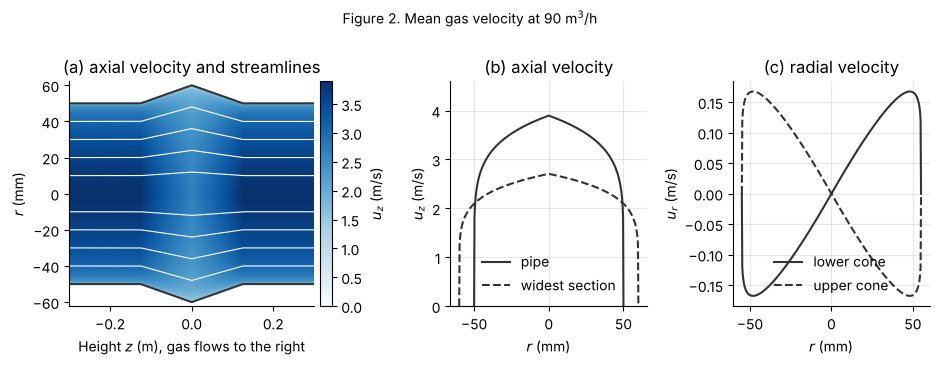

In [2]:
Q = 90 / 3600                                 # m3/s
eta = np.linspace(0, 1, 20001)                # r / r_w
for z in (-0.5, -0.06, 0.0, 0.06):
    R = wall(z)
    flux = trapezoid(gas_field(eta * R, z, Q)[1] * 2 * np.pi * eta * R, eta * R)
    print(f"z = {z:+.2f} m: flow rate through the section / Q = {flux / Q:.4f}")
rr, zz = np.meshgrid(np.linspace(1e-3, 0.040, 400), np.linspace(-0.115, -0.010, 400), indexing="ij")   # inside the lower cone
ur, uz = gas_field(rr, zz, Q)
div = np.gradient(rr * ur, rr[:, 0], axis=0) / rr + np.gradient(uz, zz[0], axis=1)
print(f"largest divergence in the lower cone, relative to (mean velocity) / (wall radius): {np.abs(div[2:-2, 2:-2]).max() * wall(0) / (Q / area(0)):.1e}")
def ur_by_integration(r, z, Q, n=2001, dz=1e-5):   # u_r = -(1/r) * integral from 0 to r of s (du_z/dz) ds, by trapezoids
    s = np.linspace(0.0, r, n)
    duz_dz = (gas_field(s, z + dz, Q)[1] - gas_field(s, z - dz, Q)[1]) / (2 * dz)
    return -trapezoid(s * duz_dz, s) / r
points = ((0.010, -0.100), (0.020, -0.050), (0.010, 0.050), (0.025, 0.100))   # (r, z) in m, inside the two cones
diff = max(abs(ur_by_integration(r, z, Q) - gas_field(r, z, Q)[0]) for r, z in points)
print(f"radial velocity at four points in the cones, closed form minus numerical integration of continuity: at most {diff:.0e} m/s")

fig, ax = plt.subplots(1, 3, figsize=(9.5, 3.6), gridspec_kw={"width_ratios": [1.5, 1, 1]})
zz = np.linspace(-0.3, 0.3, 400)
rr = np.linspace(-0.062, 0.062, 300)
ZZ, RR = np.meshgrid(zz, rr)
UR, UZ = gas_field(RR, ZZ, Q)
UZ = np.where(np.abs(RR) <= wall(ZZ), UZ, np.nan)
im = ax[0].pcolormesh(zz, 1e3 * rr, UZ, cmap="Blues", vmin=0, shading="auto")
for e in (-0.8, -0.6, -0.4, -0.2, 0.2, 0.4, 0.6, 0.8):
    ax[0].plot(zz, 1e3 * e * wall(zz), color="white", lw=0.8)
ax[0].plot(zz, 1e3 * wall(zz), color="0.2", lw=1.5); ax[0].plot(zz, -1e3 * wall(zz), color="0.2", lw=1.5)
ax[0].set(xlabel="Height $z$ (m), gas flows to the right", ylabel="$r$ (mm)", title="(a) axial velocity and streamlines")
ax[0].grid(False)
fig.colorbar(im, ax=ax[0], label="$u_z$ (m/s)", pad=0.02)
for z, label, ls in ((0.3, "pipe", "-"), (0.0, "widest section", "--")):
    r = np.linspace(-wall(z), wall(z), 401)
    ax[1].plot(1e3 * r, gas_field(r, z, Q)[1], ls, color="0.2", label=label)
ax[1].set(xlabel="$r$ (mm)", ylabel="$u_z$ (m/s)", title="(b) axial velocity", ylim=(0, 4.6))
ax[1].legend(frameon=False, loc="lower center")
for z, label, ls in ((-h / 2, "lower cone", "-"), (h / 2, "upper cone", "--")):
    r = np.linspace(-wall(z), wall(z), 401)
    ax[2].plot(1e3 * r, gas_field(r, z, Q)[0], ls, color="0.2", label=label)
ax[2].set(xlabel="$r$ (mm)", ylabel="$u_r$ (m/s)", title="(c) radial velocity")
ax[2].legend(frameon=False, loc="lower center")
fig.suptitle("Figure 2. Mean gas velocity at 90 m$^3$/h", y=1.0, fontsize=10)
plt.tight_layout()
plt.show()

The flow rate through every cross-section equals $Q$ and the divergence vanishes to the accuracy of the finite differences, so the velocity field conserves mass. The radial velocity from the numerical integration agrees with the closed form of Section 2.2 to better than $10^{-8}$ m/s. At 90 m$^3$/h the mean velocity falls from 3.2 m/s in the pipes to 2.2 m/s in the widest section. The radial velocity reaches about 0.17 m/s. It points outward in the lower cone and inward in the upper cone, so a foil that hovers in the lower cone is carried toward the wall, where the gas is slower.

### 4.2 Suspension velocity

Table 1 compares the suspension velocity of a solid sphere and of a foil with the measurement of Zhu et al., and with the gas velocity available in the column.

In [3]:
sizes = {"0.625 mm": 0.625e-3, "1.25 mm": 1.25e-3, "1.75 mm": 1.75e-3, "5 mm": 5.0e-3}
rows = {(shape, metal): [suspension_velocity(shape, a, metal) for a in sizes.values()]
        for shape in ("sphere", "foil") for metal in ("Al", "Cu")}
rows[("measured (Zhu et al.)", "Al")] = [np.nan] * 3 + [2.21]
rows[("measured (Zhu et al.)", "Cu")] = [np.nan] * 3 + [3.93]
table1 = pd.DataFrame(rows, index=pd.Index(sizes.keys(), name="size")).T
print("Table 1. Suspension velocity (m/s) of a sphere of diameter a and of a foil of edge a and thickness 0.1 mm")
display(table1.style.format(precision=2, na_rep=""))
u = lambda Q, z: Q / 3600 / area(z)
print(f"Mean gas velocity at 70 to 110 m3/h: {u(70, h):.2f} to {u(110, h):.2f} m/s in the pipes, "
      f"{u(70, 0):.2f} to {u(110, 0):.2f} m/s in the widest section")
need = lambda metal, z: ", ".join(f"{v * area(z) * 3600:.0f}" for v in rows[("sphere", metal)][:3])
print(f"Flow rate (m3/h) at which the mean gas velocity equals the suspension velocity of a sphere of 0.625, 1.25, 1.75 mm: "
      f"aluminum in the widest section {need('Al', 0)}; copper in the pipes {need('Cu', h)}")

Table 1. Suspension velocity (m/s) of a sphere of diameter a and of a foil of edge a and thickness 0.1 mm


Mean gas velocity at 70 to 110 m3/h: 2.48 to 3.89 m/s in the pipes, 1.72 to 2.70 m/s in the widest section
Flow rate (m3/h) at which the mean gas velocity equals the suspension velocity of a sphere of 0.625, 1.25, 1.75 mm: aluminum in the widest section 194, 351, 439; copper in the pipes 284, 470, 556


The foil law gives 2.19 m/s for aluminum and 3.98 m/s for copper at the size used in the suspension test, within 1.3% of the measured 2.21 and 3.93 m/s. For the three sieve classes it gives 1.9 to 2.1 m/s for aluminum and 3.5 to 3.9 m/s for copper, values that bracket the mean gas velocity in the pipes. A solid sphere of the same size needs 4.8 to 19.7 m/s, more than the mean gas velocity at any flow rate in the operating range, so a sphere cannot stand in for a foil. Spheres of the two metals would still separate, because their suspension velocities differ by a factor of about two, but only at flow rates of roughly 200 to 550 m$^3$/h, two to five times the operating range. This is not an operating point of the separator, which works best at 75 to 89 m$^3$/h. It shows that the feed cannot consist of compact particles. A sphere of 1.25 mm weighs 6.5 times as much as a 0.1 mm thick foil of the same size and offers the gas a similar area. The foil drag law is used in all simulations that follow.

### 4.3 Single particles over the operating range

A foil of the mid-size of each sieve class is released at rest at the widest section and followed until it reaches an outlet, for nine flow rates in steady and in pulsed flow. Table 2 lists the outcome of all 108 simulations, the outlet reached and the time needed, or "held" if the foil is still in the column after 30 s. Figure 3 shows the trajectories of the 1.5 to 1 mm class at three flow rates.

In [4]:
mid = {"2 ~ 1.5 mm": 1.75e-3, "1.5 ~ 1 mm": 1.25e-3, "1 ~ 0.25 mm": 0.625e-3}
rows = {}
for mode, A in (("steady", 0.0), ("pulsed", amp_pulse)):
    for name, a in mid.items():
        for metal in ("Al", "Cu"):
            out = [simulate("foil", a, metal, Q, A) for Q in flows]
            rows[(mode, name, metal)] = ["held" if fate == "held" else f"{fate} {t[-1]:.1f} s" for t, z, fate in out]
table2 = pd.DataFrame(rows, index=pd.Index(flows, name="Qc (m3/h)")).T
shade = lambda v: "background-color: " + ("#dbe9f6" if v.startswith("top") else "#f9dcdc" if v.startswith("bottom") else "#e4e4e4")
print("Table 2. Outlet reached by a single foil and time to reach it (top = overflow, bottom = underflow)")
display(table2.style.map(shade))

Table 2. Outlet reached by a single foil and time to reach it (top = overflow, bottom = underflow)


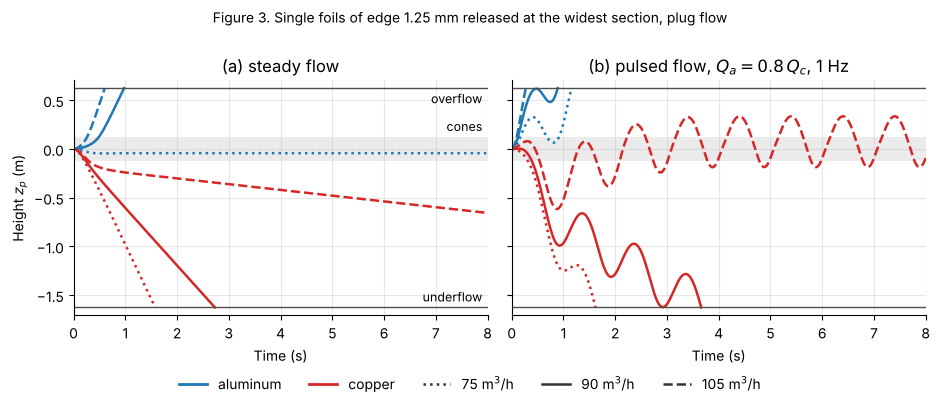

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.7), sharey=True)
styles = {75: ":", 90: "-", 105: "--"}
for k, (title, A) in enumerate((("(a) steady flow", 0.0), ("(b) pulsed flow, $Q_a = 0.8\\,Q_c$, 1 Hz", amp_pulse))):
    ax[k].axhspan(-h, h, color="0.92", lw=0)
    for Q, ls in styles.items():
        for metal in ("Al", "Cu"):
            t, z, fate = simulate("foil", 1.25e-3, metal, Q, A, T=8.0)
            ax[k].plot(t, z, ls, color=color[metal], lw=1.8)
    ax[k].axhline(z_top, color="0.3", lw=1); ax[k].axhline(z_bot, color="0.3", lw=1)
    ax[k].set(title=title, xlabel="Time (s)", xlim=(0, 8), ylim=(z_bot - 0.08, z_top + 0.08))
ax[0].set_ylabel("Height $z_p$ (m)")
ax[0].text(7.9, z_top - 0.03, "overflow", ha="right", va="top", fontsize=9); ax[0].text(7.9, z_bot + 0.03, "underflow", ha="right", va="bottom", fontsize=9)
ax[0].text(7.9, h + 0.03, "cones", ha="right", va="bottom", fontsize=9)
handles = [Line2D([], [], color=color["Al"], lw=2, label="aluminum"), Line2D([], [], color=color["Cu"], lw=2, label="copper")]
handles += [Line2D([], [], color="0.2", ls=ls, lw=1.8, label=f"{Q} m$^3$/h") for Q, ls in styles.items()]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("Figure 3. Single foils of edge 1.25 mm released at the widest section, plug flow", y=1.0, fontsize=10)
plt.tight_layout()
plt.show()

In steady flow the aluminum foil reaches the overflow only above a threshold flow rate, which is 90, 85 and 80 m$^3$/h for the three classes. Below the threshold the foil is held in the lower cone, at the height where the gas velocity equals its suspension velocity (dotted blue line in Figure 3a). This position is stable because the gas velocity increases downward in the lower cone. The copper foil reaches the underflow up to 105 m$^3$/h (95 m$^3$/h for the finest class), more slowly as the flow rate increases, and is held above that. Steady flow therefore separates the two metals between 90 and 105 m$^3$/h for the coarsest class, 85 and 105 m$^3$/h for the middle class and 80 and 95 m$^3$/h for the finest.

Pulsation releases the held aluminum, which then reaches the overflow at every flow rate. It also lowers the limit for copper to 95 m$^3$/h (90 m$^3$/h for the finest class), above which copper is held or carried to the overflow. The separation window in pulsed flow is 70 to 95 m$^3$/h (70 to 90 m$^3$/h for the finest class). In both modes the thresholds decrease with particle size, in the same direction as the optimal flow rates of 89, 84 and 75 m$^3$/h reported by Zhu et al.

### 4.4 Many particles with collisions

The next cell is the multi-particle model of Sections 2.2, 2.6 and 2.7. One call of `sweep` follows 200 foils for 20 s at each of the nine flow rates. The check at the end releases one copper foil on the axis in steady flow without fluctuations and compares its final velocity with the centerline gas velocity minus the suspension velocity.

In [6]:
import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)

dt, T_run, stride = 2.0e-3, 20.0, 10          # time step (s), simulated time (s), steps between stored frames
e_rest = 0.4                                  # restitution coefficient, particle-particle and particle-wall
x_al = 52.49 / (52.49 + 64.37)                # aluminum mass fraction of the foils (Zhu et al.)
n_al = round(200 * (x_al / rho["Al"]) / (x_al / rho["Al"] + (1 - x_al) / rho["Cu"]))
n_cu = 200 - n_al

def wall_j(z): return r2 - (r2 - r1) * jnp.minimum(jnp.abs(z), h) / h

def gas(r, z, t, Qc, Qa):                     # mean gas velocity, friction velocity and eddy lifetime (Section 2.2)
    R = wall_j(z)
    ubar = (Qc + Qa * jnp.cos(2 * jnp.pi * f_pulse * t)) / (jnp.pi * R**2)
    uz = 60 / 49 * ubar * jnp.clip(1 - jnp.abs(r) / R, 0.0, 1.0) ** (1 / 7)
    ur = uz * r / R * jnp.where(jnp.abs(z) < h, -(r2 - r1) / h * jnp.sign(z), 0.0)
    u_tau = ubar * jnp.sqrt(0.316 / 8) * (2 * R * ubar / nu) ** (-1 / 8)
    return ur, uz, u_tau, 0.07 * R / u_tau

def collision_kick(r, z, vr, vz, rad, mass, active):
    """Velocity change of every foil from hard-sphere impulses with all foils it touches within dt (Section 2.6)."""
    dx, dz = r[:, None] - r[None, :], z[:, None] - z[None, :]
    dvx, dvz = vr[:, None] - vr[None, :], vz[:, None] - vz[None, :]
    S = rad[:, None] + rad[None, :]
    b = dx * dvx + dz * dvz                                               # negative when the pair approaches
    w2 = dvx**2 + dvz**2 + 1e-30
    c = dx**2 + dz**2 - S**2
    disc = b**2 - w2 * c
    tc = jnp.where(c < 0, 0.0, (-b - jnp.sqrt(jnp.maximum(disc, 0.0))) / w2)   # time of first contact
    hit = active[:, None] & active[None, :] & (b < 0) & (disc > 0) & (tc <= dt) & ~jnp.eye(r.shape[0], dtype=bool)
    nx, nz = dx + dvx * tc, dz + dvz * tc                                 # line of centers at contact
    J = jnp.where(hit, -(1 + e_rest) * (dvx * nx + dvz * nz) / (nx**2 + nz**2 + 1e-30) * mass[None, :] / (mass[:, None] + mass[None, :]), 0.0)
    return jnp.sum(J * nx, axis=1), jnp.sum(J * nz, axis=1)

def run(p, Qc, Qa, turb):
    """Follows the foils in p for T_run seconds. turb = 1 switches the turbulent fluctuations on, 0 off.
    Returns the final state and frames of (r, z, status)."""
    n = p["r0"].shape[0]
    def step(state, k):
        r, z, vr, vz, status, fr, fz, key = state
        t = k * dt
        active = (status == 0) & (t >= p["t_feed"])                       # fed and not yet collected
        kr, kz = collision_kick(r, z, vr, vz, p["rad"], p["mass"], active)
        vr, vz = vr + kr, vz + kz
        ur, uz, u_tau, tau_e = gas(r, z, t, Qc, Qa)
        slip = jnp.sqrt((ur + fr - vr)**2 + (uz + fz - vz)**2) + 1e-9
        a = jnp.exp(-dt / jnp.minimum(tau_e, u_tau * tau_e / slip))       # correlation over one step: eddy lifetime or crossing time
        key, sub = jax.random.split(key)
        kick = (turb * u_tau * jnp.sqrt(1 - a**2))[:, None] * jax.random.normal(sub, (n, 2))
        fr, fz = a * fr + kick[:, 0], a * fz + kick[:, 1]                  # fluctuation u' seen by each foil
        sr, sz = ur + fr - vr, uz + fz - vz                               # slip velocity
        s = jnp.sqrt(sr**2 + sz**2)
        vr_n, vz_n = vr + p["beta"] * s * sr * dt, vz + (p["beta"] * s * sz - p["grav"]) * dt
        r_n, z_n = r + vr_n * dt, z + vz_n * dt
        R = wall_j(z_n) - p["rad"]                                        # wall reflection
        vr_n = jnp.where(jnp.abs(r_n) > R, -e_rest * jnp.abs(vr_n) * jnp.sign(r_n), vr_n)
        r_n = jnp.clip(r_n, -R, R)
        r, z, vr, vz = [jnp.where(active, new, old) for new, old in ((r_n, r), (z_n, z), (vr_n, vr), (vz_n, vz))]
        status = jnp.where(active & (z >= z_top), 1, jnp.where(active & (z <= z_bot), -1, status))
        return (r, z, vr, vz, status, fr, fz, key), None
    def frame(state, i):
        state, _ = jax.lax.scan(step, state, i * stride + jnp.arange(stride))
        return state, (state[0], state[1], state[4])
    start = (p["r0"], p["z0"], p["vr0"], p["vz0"], jnp.zeros(n, dtype=jnp.int32), jnp.zeros(n), jnp.zeros(n), jax.random.PRNGKey(0))
    return jax.lax.scan(frame, start, jnp.arange(int(round(T_run / dt)) // stride))

sweep = jax.jit(jax.vmap(run, in_axes=(None, 0, 0, None)))                # all flow rates of one sweep together

def make_feed(lo, hi, n_al=n_al, n_cu=n_cu, seed=0):
    rng = np.random.default_rng(seed)
    n = n_al + n_cu
    is_al = np.arange(n) < n_al
    a = rng.uniform(lo, hi, n)
    d, cd = foil(a)
    rho_p = np.where(is_al, rho["Al"], rho["Cu"])
    phi = 3 / (2 * rho_p / rho_g + 1)
    p = dict(beta=phi * cd / (2 * d), grav=(1 - phi) * g, rad=a / 2, mass=rho_p * a**2 * H, t_feed=rng.uniform(0, 2, n),
             r0=rng.uniform(-0.025, 0.025, n), z0=rng.uniform(-0.05, 0.05, n), vr0=rng.uniform(-0.5, 0.5, n), vz0=np.full(n, -0.2))
    return {k: jnp.asarray(v) for k, v in p.items()}, is_al

# check: one copper foil on the axis in steady flow at 80 m3/h, fluctuations off
p1, _ = make_feed(1.25e-3, 1.25e-3, n_al=0, n_cu=1)
p1.update(r0=jnp.zeros(1), vr0=jnp.zeros(1), t_feed=jnp.zeros(1))
state, _ = jax.jit(run)(p1, 80 / 3600, 0.0, 0.0)
print(f"Check: copper foil on the axis leaves at v_z = {float(state[3][0]):+.3f} m/s; "
      f"centerline gas velocity minus suspension velocity = {60 / 49 * 80 / 3600 / area(h) - suspension_velocity('foil', 1.25e-3, 'Cu'):+.3f} m/s")

Check: copper foil on the axis leaves at v_z = -0.308 m/s; centerline gas velocity minus suspension velocity = -0.308 m/s


In [7]:
def split(p, is_al, status):                  # recovery, grade and hold-up (%) from the outlet reached by each foil
    m = np.asarray(p["mass"])
    top, bot, held = status == 1, status == -1, status == 0
    pct = lambda x, y: 100 * x.sum() / y.sum() if y.sum() > 0 else np.nan
    return {"Al recovery": pct(m[is_al & top], m[is_al]), "Cu recovery": pct(m[~is_al & bot], m[~is_al]),
            "Al grade": pct(m[is_al & top], m[top]), "Cu grade": pct(m[~is_al & bot], m[bot]), "held": pct(m[held], m)}

results, frames, no_turbulence = {}, {}, {}
for name, (lo, hi) in classes.items():
    p, is_al = make_feed(lo, hi)
    for mode, A in (("steady", 0.0), ("pulsed", amp_pulse)):
        state, fr = sweep(p, jnp.asarray(flows) / 3600, A * jnp.asarray(flows) / 3600, 1.0)
        results[mode, name] = pd.DataFrame([split(p, is_al, s) for s in np.asarray(state[4])], index=flows)
        frames[mode, name] = [np.asarray(x) for x in fr] + [is_al, np.asarray(p["t_feed"])]
        if name == "1.5 ~ 1 mm":                                          # the same runs without turbulent fluctuations
            state, fr = sweep(p, jnp.asarray(flows) / 3600, A * jnp.asarray(flows) / 3600, 0.0)
            no_turbulence[mode] = pd.DataFrame([split(p, is_al, s) for s in np.asarray(state[4])], index=flows)

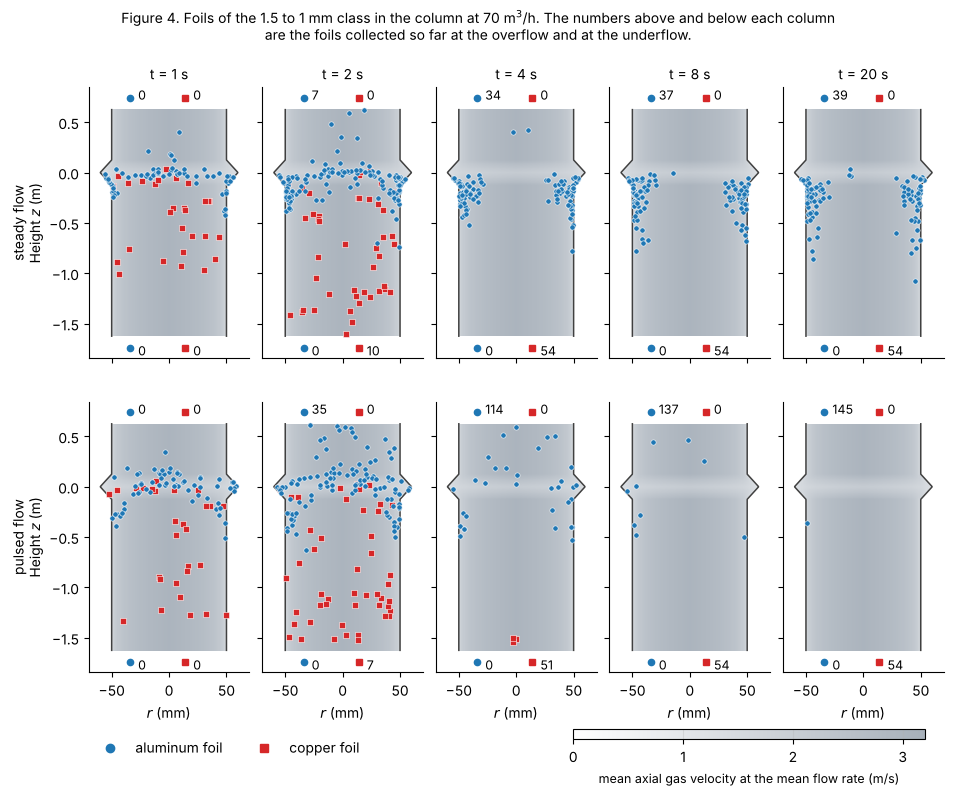

In [8]:
from matplotlib.colors import LinearSegmentedColormap
gas_cmap = LinearSegmentedColormap.from_list("gas", ["#ffffff", "#a7b0ba"])   # white (gas at rest) to gray (fastest gas)

def snapshots(axs, mode, name, Q, times):
    r, z, status, is_al, t_feed = frames[mode, name]
    i = list(flows).index(Q)
    zz = np.linspace(z_bot, z_top, 500)
    rr = np.linspace(-0.0605, 0.0605, 122)
    RR, ZZ = np.meshgrid(rr, zz)
    UZ = np.where(np.abs(RR) <= wall(ZZ), gas_field(RR, ZZ, Q / 3600)[1], np.nan)   # mean axial gas velocity at the mean flow rate
    for a, t in zip(axs, times):
        k = int(round(t / (stride * dt))) - 1
        im = a.pcolormesh(1e3 * rr, zz, UZ, cmap=gas_cmap, vmin=0, vmax=3.2, shading="auto", rasterized=True)
        a.plot(1e3 * wall(zz), zz, color="0.25", lw=1.1); a.plot(-1e3 * wall(zz), zz, color="0.25", lw=1.1)
        inside = (status[i, k] == 0) & (t_feed <= t)
        for metal, sel, mk in (("Cu", ~is_al, "s"), ("Al", is_al, "o")):
            a.plot(1e3 * r[i, k][inside & sel], z[i, k][inside & sel], mk, ms=3.8, color=color[metal], mec="white", mew=0.4)
        top, bot = status[i, k] == 1, status[i, k] == -1
        for y, sel, va in ((z_top + 0.07, top, "bottom"), (z_bot - 0.07, bot, "top")):          # foils collected so far at each outlet
            for x, metal, n, mk in ((-34, "Al", (sel & is_al).sum(), "o"), (14, "Cu", (sel & ~is_al).sum(), "s")):
                a.plot(x, y + (0.045 if va == "bottom" else -0.045), mk, ms=4.5, color=color[metal], clip_on=False)
                a.text(x + 7, y, f"{n}", ha="left", va=va, fontsize=9)
        a.set(xlim=(-70, 70), ylim=(z_bot - 0.22, z_top + 0.22), xticks=[-50, 0, 50])
        a.grid(False)
    return im

times, Q_show = (1, 2, 4, 8, 20), 70
fig, ax = plt.subplots(2, 5, figsize=(9.5, 7.8), sharex=True, sharey=True)
for row, mode in enumerate(("steady", "pulsed")):
    im = snapshots(ax[row], mode, "1.5 ~ 1 mm", Q_show, times)
    ax[row, 0].set_ylabel(f"{mode} flow\nHeight $z$ (m)")
for a, t in zip(ax[0], times): a.set_title(f"t = {t} s", fontsize=10, pad=6)
for a in ax[1]: a.set_xlabel("$r$ (mm)")
handles = [Line2D([], [], marker="o", ls="", color=color["Al"], label="aluminum foil"), Line2D([], [], marker="s", ls="", color=color["Cu"], label="copper foil")]
fig.subplots_adjust(left=0.09, right=0.99, top=0.885, bottom=0.135, wspace=0.08, hspace=0.16)
fig.legend(handles=handles, loc="lower left", ncol=2, frameon=False, bbox_to_anchor=(0.085, 0.012))
cax = fig.add_axes([0.60, 0.050, 0.37, 0.013])
fig.colorbar(im, cax=cax, orientation="horizontal", ticks=[0, 1, 2, 3]).set_label("mean axial gas velocity at the mean flow rate (m/s)", fontsize=9)
fig.suptitle(f"Figure 4. Foils of the 1.5 to 1 mm class in the column at {Q_show} m$^3$/h. The numbers above and below each column\nare the foils collected so far at the overflow and at the underflow.", y=0.985, fontsize=10)
plt.show()

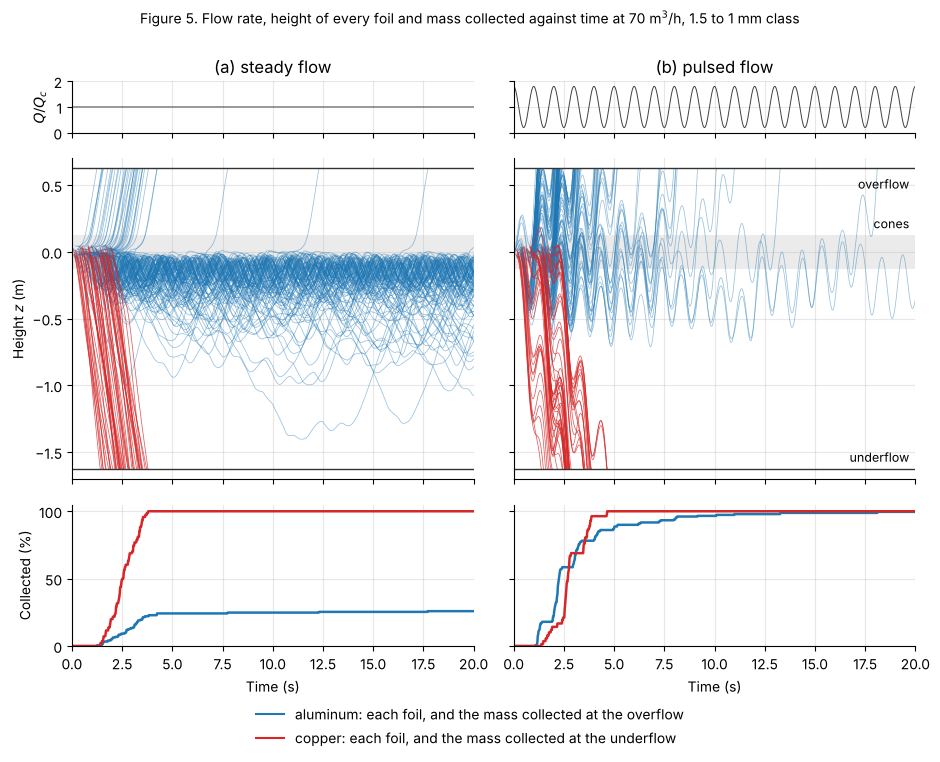

In [9]:
name, Q_show = "1.5 ~ 1 mm", 70
i = list(flows).index(Q_show)
t_frame = (np.arange(int(round(T_run / dt)) // stride) + 1) * stride * dt                  # time of each stored frame (s)
fig, ax = plt.subplots(3, 2, figsize=(9.5, 7.0), sharex=True, sharey="row", gridspec_kw={"height_ratios": [0.8, 5, 2.2]})
for k, (mode, A) in enumerate((("steady", 0.0), ("pulsed", amp_pulse))):
    r, z, status, is_al, t_feed = frames[mode, name]
    tt = np.linspace(0, T_run, 4001)
    ax[0, k].plot(tt, 1 + A * np.cos(2 * np.pi * f_pulse * tt), color="0.25", lw=0.7)
    ax[0, k].set(ylim=(0, 2), yticks=[0, 1, 2], title=f"({'ab'[k]}) {mode} flow")
    out = status[i] != 0                                                                    # collected at an outlet
    first = out & ~np.vstack([np.zeros_like(out[:1]), out[:-1]])                            # the frame in which a foil is collected
    show = (t_frame[:, None] >= t_feed[None, :]) & (~out | first)
    Z = np.where(show, np.clip(z[i], z_bot, z_top), np.nan)
    a = ax[1, k]
    a.axhspan(-h, h, color="0.92", lw=0)
    for metal, sel, alpha in (("Al", is_al, 0.45), ("Cu", ~is_al, 0.75)):
        a.plot(t_frame, Z[:, sel], color=color[metal], lw=0.55, alpha=alpha)
    a.axhline(z_top, color="0.2", lw=1); a.axhline(z_bot, color="0.2", lw=1)
    a.set(ylim=(z_bot - 0.08, z_top + 0.08), xlim=(0, T_run))
    m = np.asarray(make_feed(*classes[name])[0]["mass"])
    for metal, sel, outlet, ls in (("Al", is_al, 1, "-"), ("Cu", ~is_al, -1, "-")):
        ax[2, k].plot(np.r_[0, t_frame], np.r_[0, 100 * ((status[i] == outlet) * m)[:, sel].sum(axis=1) / m[sel].sum()], ls, color=color[metal], lw=1.8)
    ax[2, k].set(ylim=(0, 105), yticks=[0, 50, 100], xlabel="Time (s)")
ax[0, 0].set_ylabel("$Q / Q_c$")
ax[1, 0].set_ylabel("Height $z$ (m)")
ax[2, 0].set_ylabel("Collected (%)")
for text, y in (("overflow", z_top - 0.06), ("cones", h + 0.03), ("underflow", z_bot + 0.03)):
    ax[1, 1].text(T_run - 0.3, y, text, ha="right", va="top" if text == "overflow" else "bottom", fontsize=9)
handles = [Line2D([], [], color=color["Al"], label="aluminum: each foil, and the mass collected at the overflow"),
           Line2D([], [], color=color["Cu"], label="copper: each foil, and the mass collected at the underflow")]
fig.legend(handles=handles, loc="lower center", ncol=1, frameon=False, bbox_to_anchor=(0.5, -0.07))
fig.suptitle(f"Figure 5. Flow rate, height of every foil and mass collected against time at {Q_show} m$^3$/h, 1.5 to 1 mm class", y=1.0, fontsize=10)
plt.tight_layout()
plt.show()

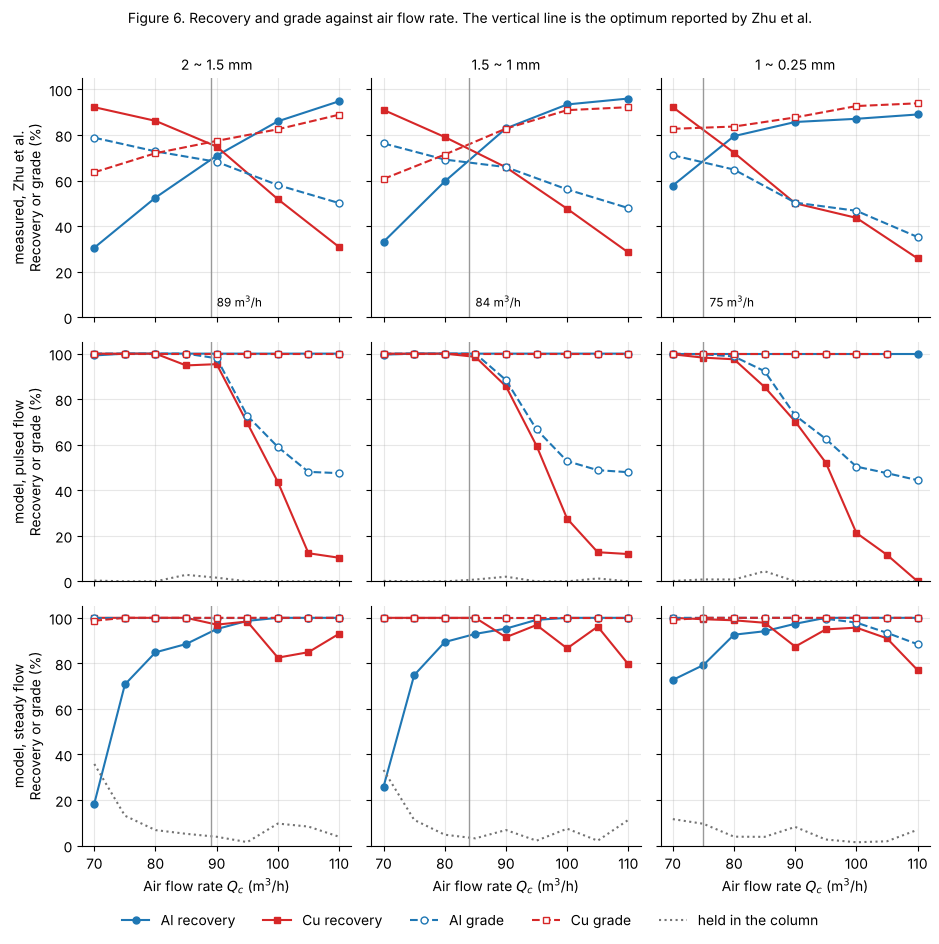

Table 3. Flow rate (m3/h) at which each recovery passes 50%


Al recovery rises to 50% at                              \
                               measured model, steady model, pulsed   
2 ~ 1.5 mm                           79            73      below 70   
1.5 ~ 1 mm                           76            72      below 70   
1 ~ 0.25 mm                    below 70      below 70      below 70   

            Cu recovery falls to 50% at                              
                               measured model, steady model, pulsed  
2 ~ 1.5 mm                          101     above 110            99  
1.5 ~ 1 mm                           99     above 110            96  
1 ~ 0.25 mm                          90     above 110            95

In [10]:
zhu_Q = [70, 80, 90, 100, 110]                # read from Fig. 4 of Zhu et al. (2021), reading error about 1 point
zhu = {"2 ~ 1.5 mm":  {"Al recovery": [30.5, 52.5, 70.9, 86.0, 94.8], "Cu recovery": [92.2, 86.2, 74.9, 51.8, 30.8],
                       "Al grade": [78.8, 72.8, 68.2, 58.0, 50.1], "Cu grade": [63.6, 72.0, 77.4, 82.5, 88.9]},
       "1.5 ~ 1 mm":  {"Al recovery": [33.1, 59.6, 82.9, 93.4, 96.0], "Cu recovery": [91.0, 79.1, 65.8, 47.6, 28.4],
                       "Al grade": [76.3, 69.2, 65.9, 56.1, 47.9], "Cu grade": [60.7, 71.4, 82.8, 90.9, 92.2]},
       "1 ~ 0.25 mm": {"Al recovery": [57.8, 79.5, 85.7, 87.1, 89.0], "Cu recovery": [92.2, 72.2, 50.0, 43.6, 25.8],
                       "Al grade": [71.1, 64.8, 50.3, 46.7, 35.2], "Cu grade": [82.7, 83.7, 87.7, 92.7, 93.9]}}
zhu_opt = {"2 ~ 1.5 mm": 89, "1.5 ~ 1 mm": 84, "1 ~ 0.25 mm": 75}
look = {"Al recovery": dict(color=color["Al"], ls="-", marker="o"), "Cu recovery": dict(color=color["Cu"], ls="-", marker="s"),
        "Al grade": dict(color=color["Al"], ls="--", marker="o", mfc="white"), "Cu grade": dict(color=color["Cu"], ls="--", marker="s", mfc="white")}

fig, ax = plt.subplots(3, 3, figsize=(9.5, 9.0), sharex=True, sharey=True)
for j, name in enumerate(classes):
    data = [pd.DataFrame(zhu[name], index=zhu_Q), results["pulsed", name], results["steady", name]]
    for i, df in enumerate(data):
        for key, kw in look.items():
            ax[i, j].plot(df.index, df[key], lw=1.5, ms=5, **kw)
        if i > 0:
            ax[i, j].plot(df.index, df["held"], color="0.45", ls=":", lw=1.5)
        ax[i, j].axvline(zhu_opt[name], color="0.6", lw=1)
    ax[0, j].set_title(name, fontsize=10)
    ax[0, j].text(zhu_opt[name] + 1, 3, f"{zhu_opt[name]} m$^3$/h", fontsize=8.5, va="bottom")
    ax[2, j].set_xlabel("Air flow rate $Q_c$ (m$^3$/h)")
for i, label in enumerate(("measured, Zhu et al.", "model, pulsed flow", "model, steady flow")):
    ax[i, 0].set_ylabel(f"{label}\nRecovery or grade (%)")
ax[0, 0].set(ylim=(0, 105), xticks=range(70, 111, 10))
handles = [Line2D([], [], lw=1.5, ms=5, label=key, **kw) for key, kw in look.items()] + [Line2D([], [], color="0.45", ls=":", label="held in the column")]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.035))
fig.suptitle("Figure 6. Recovery and grade against air flow rate. The vertical line is the optimum reported by Zhu et al.", y=1.0, fontsize=10)
plt.tight_layout()
plt.show()

def half(curve, rising):                      # flow rate at which a recovery passes 50%, by linear interpolation
    Q, y = np.asarray(curve.index, float), curve.to_numpy() if rising else 100 - curve.to_numpy()
    if y[0] >= 50: return f"below {Q[0]:.0f}"
    if not (y >= 50).any(): return f"above {Q[-1]:.0f}"
    i = np.argmax(y >= 50)
    return f"{Q[i - 1] + (50 - y[i - 1]) / (y[i] - y[i - 1]) * (Q[i] - Q[i - 1]):.0f}"

table3 = {}
for name in classes:
    sets = {"measured": pd.DataFrame(zhu[name], index=zhu_Q), "model, steady": results["steady", name], "model, pulsed": results["pulsed", name]}
    table3[name] = {("Al recovery rises to 50% at", k): half(df["Al recovery"], True) for k, df in sets.items()}
    table3[name].update({("Cu recovery falls to 50% at", k): half(df["Cu recovery"], False) for k, df in sets.items()})
print("Table 3. Flow rate (m3/h) at which each recovery passes 50%")
display(pd.DataFrame(table3).T)

Figure 4 shows what the two flow modes do to the same feed at 70 m$^3$/h, and Figure 5 follows every foil in time. The gray shading in Figure 4 is the mean gas velocity, which is lowest in the widest section. Copper falls to the underflow in both modes and is collected completely within 5 s. In steady flow about a quarter of the aluminum reaches the overflow. The rest stays in and below the lower cone, carried toward the wall by the radial gas velocity, and neither rises nor falls. Its lines in Figure 5a remain below the widest section until the end of the run, most of them within 0.5 m of it. In pulsed flow the same foils move up and down with the pulse (Figure 5b), and almost all of the aluminum has left through the overflow after 8 s.

Figure 6 compares the recovery and grade of the model with the measurements of Zhu et al., which were read from their Figure 4 with a reading error of about one point. The two flow modes bracket the measurements. In steady flow the aluminum recovery rises steeply with the flow rate, as measured, because below about 90 m$^3$/h part of the aluminum is held in the column. Almost no copper reaches the overflow, so the aluminum grade stays near 100%, and at high flow rates some copper is held instead. In pulsed flow the aluminum is recovered completely at every flow rate, and the copper recovery and the aluminum grade fall above 85 to 90 m$^3$/h, as measured, because copper is carried into the overflow. At 110 m$^3$/h nearly all of the copper leaves with the aluminum, and the aluminum grade approaches the aluminum content of the feed, 45%, close to the measured 35 to 50%.

Table 3 makes the comparison quantitative with the flow rate at which each recovery passes 50%. The steady model places this point for aluminum 3 to 6 m$^3$/h below the measurement, and the pulsed model places it for copper within 5 m$^3$/h of the measurement. No parameter was fitted to these curves. Neither flow mode alone reproduces both metals. The steady model follows the measured aluminum recovery and the pulsed model the measured copper recovery, which suggests that the pulsation in the experiment was weaker than the assumed $Q_a = 0.8\,Q_c$. The pulsation amplitude of the experiment is not known, and the measurements are consistent with an amplitude between the two computed cases.

The model separates more sharply than the experiment. Between 70 and 80 m$^3$/h the pulsed model recovers at least 98% of both metals, whereas the measured recoveries never exceed 96% and the measured grades stay below 95%. All foils in the model have the same thickness and an ideal shape. Crushed fragments vary in thickness, are bent and may carry residual coating, which spreads their suspension velocities. This variability of the feed, more than the gas flow, is the likely reason for the gradual measured curves.

Each curve is one realization of 200 foils, of which 54 are copper, so single points of the copper curves scatter by up to about 10 points. The collisions also amplify rounding differences. A run on a second computer with another version of JAX changed single points by up to 8 points and the values in Table 3 by 1 m$^3$/h, and left the trends unchanged.

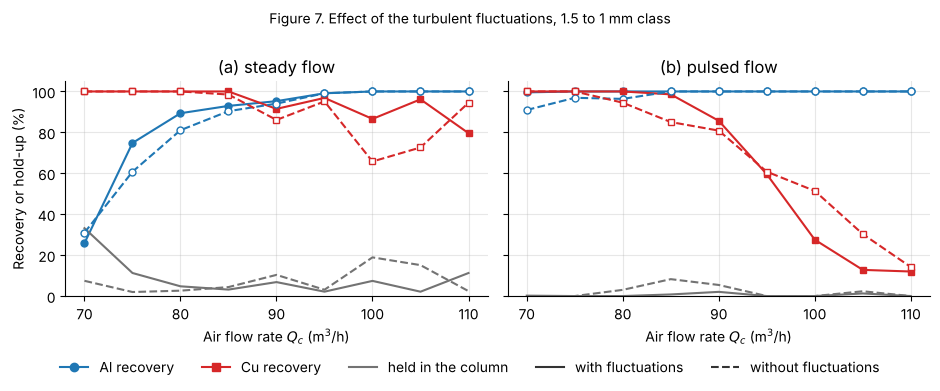

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.5), sharey=True)
for k, mode in enumerate(("steady", "pulsed")):
    for df, ls, mfc in ((results[mode, "1.5 ~ 1 mm"], "-", None), (no_turbulence[mode], "--", "white")):
        ax[k].plot(df.index, df["Al recovery"], ls, marker="o", ms=5, lw=1.5, color=color["Al"], mfc=mfc)
        ax[k].plot(df.index, df["Cu recovery"], ls, marker="s", ms=5, lw=1.5, color=color["Cu"], mfc=mfc)
        ax[k].plot(df.index, df["held"], ls, lw=1.5, color="0.45")
    ax[k].set(title=f"({'ab'[k]}) {mode} flow", xlabel="Air flow rate $Q_c$ (m$^3$/h)", ylim=(0, 105), xticks=range(70, 111, 10))
ax[0].set_ylabel("Recovery or hold-up (%)")
handles = [Line2D([], [], marker="o", color=color["Al"], label="Al recovery"), Line2D([], [], marker="s", color=color["Cu"], label="Cu recovery"),
           Line2D([], [], color="0.45", label="held in the column"), Line2D([], [], color="0.2", ls="-", label="with fluctuations"),
           Line2D([], [], color="0.2", ls="--", label="without fluctuations")]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Figure 7. Effect of the turbulent fluctuations, 1.5 to 1 mm class", y=1.0, fontsize=10)
plt.tight_layout()
plt.show()

Figure 7 repeats the runs of the 1.5 to 1 mm class without the turbulent fluctuations. The fluctuations change single recoveries by up to about 25 points and leave the shape of the curves unchanged. Their main effect is on foils near the wall. Without fluctuations a foil can slide down along the wall, where the mean gas velocity is low. With fluctuations it is kicked back into the faster gas and stays in the column, which raises the hold-up at 70 m$^3$/h in steady flow from less than 10% to about a third of the feed.

## 5. Progress since the proof of concept

The proof of concept solved the one-dimensional force balance for spherical particles in a prescribed plug flow. Particles were followed for a fixed time, and the result was the difference in velocity and displacement between pulsed and steady flow for aluminum and copper populations. The work since then has added the following.

1. **Foil drag law.** The sphere drag law has been replaced by the equivalent diameter law for foils and checked against the measured suspension velocities (Table 1). This moved the suspension velocities from 5 to 20 m/s into the range of the gas velocity in the separator, which is the precondition for predicting recovery.
2. **Outlet-based classification.** Trajectories now end at the overflow or the underflow through event detection, so every particle has a definite fate. Table 2 summarizes all single-particle simulations over the operating range.
3. **Two-dimensional gas velocity field.** The plug flow has been replaced by a power-law profile with the radial velocity required by continuity, checked numerically (Section 4.1), and by turbulent fluctuations scaled with the friction velocity.
4. **Multi-particle model.** Two hundred foils per run move in this gas field, collide with each other and with the wall, and are collected at the outlets (Figures 4 and 5). The model is vectorized in JAX and the nine flow rates of a sweep are simulated together.
5. **Recovery and grade curves.** The model now produces the quantities measured by Zhu et al. and is compared with their data for the three sieve classes (Figure 6, Table 3).
6. **Roles of the pulsation and of the variable diameter.** The simulations show that the lower cone holds particles whose suspension velocity lies between the gas velocities of the widest section and of the pipe, and that pulsation releases them.

## 6. Remaining work

1. **Variability of the feed.** The model separates more sharply than the experiment. Distributions of foil thickness and shape, and the tumbling of the foils, are the first extension. The orientation of non-spherical particles in turbulence is reviewed by Voth and Soldati (2017), and Tinklenberg et al. (2024) measured the settling of thin disks of 0.3 to 3 mm in turbulent air, a size range similar to the foils considered here.
2. **Pulsation parameters.** The frequency and $Q_a/Q_c$ are not reported. They will be varied systematically, and $Q_a/Q_c$ will be estimated by fitting the measured recoveries.
3. **Turbulence near the wall.** The fluctuations are uniform across the section. In a real pipe they vanish at the wall, which matters for the foils that collect there.
4. **Hold-up.** A continuous feed and longer runs are needed to decide where held material finally leaves. At high loading the effect of the particles on the gas has to be included.
5. **Collisions.** The collisions will be extended to three dimensions, and the influence of the assumed restitution coefficient has to be quantified.
6. **Coupled air flow.** $Q(t)$ will be obtained from the pressure-driven momentum balance of the air instead of being prescribed.

## 7. References

Bradbury, J.; Frostig, R.; Hawkins, P.; Johnson, M. J.; Leary, C.; Maclaurin, D.; Necula, G.; Paszke, A.; VanderPlas, J.; Wanderman-Milne, S.; Zhang, Q. *JAX: Composable Transformations of Python+NumPy Programs*, 2018. http://github.com/jax-ml/jax.

Crowe, C. T.; Schwarzkopf, J. D.; Sommerfeld, M.; Tsuji, Y. *Multiphase Flows with Droplets and Particles*, 2nd ed.; CRC Press, 2011.

Cundall, P. A.; Strack, O. D. L. A Discrete Numerical Model for Granular Assemblies. *Géotechnique* 1979, 29 (1), 47–65.

Gosman, A. D.; Ioannides, E. Aspects of Computer Simulation of Liquid-Fueled Combustors. *Journal of Energy* 1983, 7 (6), 482–490.

Harper, G.; Sommerville, R.; Kendrick, E.; et al. Recycling Lithium-Ion Batteries from Electric Vehicles. *Nature* 2019, 575, 75–86.

Hoomans, B. P. B.; Kuipers, J. A. M.; Briels, W. J.; van Swaaij, W. P. M. Discrete Particle Simulation of Bubble and Slug Formation in a Two-Dimensional Gas-Fluidised Bed: A Hard-Sphere Approach. *Chemical Engineering Science* 1996, 51 (1), 99–118.

Li, D.; Wang, L.; Wei, L.; Qu, Q.; Wang, J. A Study of the Dynamic Mechanism in Low-Rank Coal Separation with Varying-Diameter Pulsed Airflow Separator. *Coal Preparation Technology* 2023, 51 (2), 9–13. DOI: 10.16447/j.cnki.cpt.2023.02.002.

Marchildon, E. K.; Gauvin, W. H. Effects of Acceleration, Deceleration and Particle Shape on Single-Particle Drag Coefficients in Still Air. *AIChE Journal* 1979, 25 (6), 938–948.

Reichardt, H. Vollständige Darstellung der turbulenten Geschwindigkeitsverteilung in glatten Leitungen. *Zeitschrift für Angewandte Mathematik und Mechanik* 1951, 31 (7), 208–219.

Schiller, L.; Naumann, A. Über die grundlegenden Berechnungen bei der Schwerkraftaufbereitung. *Zeitschrift des Vereines Deutscher Ingenieure* 1933, 77, 318–320.

Schlichting, H.; Gersten, K. *Boundary-Layer Theory*, 9th ed.; Springer, 2017.

Tinklenberg, A.; Guala, M.; Coletti, F. Turbulence Effect on Disk Settling Dynamics. *Journal of Fluid Mechanics* 2024, 992, A4. DOI: 10.1017/jfm.2024.534.

Voth, G. A.; Soldati, A. Anisotropic Particles in Turbulence. *Annual Review of Fluid Mechanics* 2017, 49, 249–276. DOI: 10.1146/annurev-fluid-010816-060135.

Zhu, X.; Zhang, C.; Feng, P.; Yang, X.; Yang, X. A Novel Pulsated Pneumatic Separation with Variable-Diameter Structure and Its Application in the Recycling Spent Lithium-Ion Batteries. *Waste Management* 2021, 131, 20–30. DOI: 10.1016/j.wasman.2021.05.027.

**Methods and their sources**

| Method | Used in | Source |
|---|---|---|
| Separator geometry, feed composition, sieve classes, measured recovery and grade | Sections 2.1, 2.7, 4.4 | Zhu et al. (2021) |
| Particle force balance with pressure-gradient force and added mass | Sections 2.3, 2.4 | Li et al. (2023); Crowe et al. (2011) |
| Drag coefficient of a sphere | Section 2.5 | Schiller and Naumann (1933) |
| Equivalent diameter drag law of a foil, wall correction | Section 2.5 | Zhu et al. (2021); Marchildon and Gauvin (1979) |
| One-seventh power-law velocity profile, factor 60/49, Blasius friction factor | Section 2.2 | Schlichting and Gersten (2017) |
| Radial gas velocity | Section 2.2 | Continuity equation, checked in Section 4.1 |
| Turbulent fluctuations as a random walk with eddy lifetime and crossing time | Section 2.2 | Gosman and Ioannides (1983); Crowe et al. (2011) |
| Eddy diffusivity of turbulent pipe flow | Section 2.2 | Reichardt (1951) |
| Discrete element method, soft-sphere contact | Section 2.6 | Cundall and Strack (1979) |
| Hard-sphere collision with restitution | Section 2.6 | Hoomans et al. (1996); Crowe et al. (2011) |
| Runge-Kutta integration with event detection | Section 2.8 | SciPy `solve_ivp` |
| Vectorized time stepping (`vmap`, `lax.scan`) | Section 2.8 | Bradbury et al. (2018) |

## 8. Contributions

**Stuart Schultz**

**Yogesh Panchal**

**Meining Miao**

All three authors contributed to the literature review, the preparation of the notebook and the interpretation of the results.